# Part B: Station-Level Feature Engineering and Principal Component Analysis

Trip and status records are aggregated into six station-level features covering activity, trip characteristics, and bike availability. The analysis validates records, selects stations, standardizes features, and applies Principal Component Analysis (PCA) to prepare inputs for clustering. The final table preserves original measurements alongside PC scores for group interpretation.

## 1. Data Sources

**Purpose.** Identify the input tables and their analytical roles.

| Table | Unit of observation | Analytical role |
|---|---|---|
| `stations` | One station | Station and system identifiers, location |
| `cities` | One bike-sharing system | System name and country |
| `trips` | One trip | Departures, arrivals, duration, and distance |
| `station_status` | A station at a recorded time | Available bikes and record-quality indicators |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

OUT_DIR = Path("../output/part_b")
OUT_DIR.mkdir(parents=True, exist_ok=True)

stations = pd.read_csv("../data_cleaned/cleaned_stations.csv")
cities = pd.read_csv("../data_cleaned/cities_clean.csv")
trips = pd.read_csv("../data_cleaned/trips_small_cleaned.csv")
station_status = pd.read_csv("../data_cleaned/stations_status_clean.csv")

input_summary = pd.DataFrame({
    "table": ["stations", "cities", "trips", "station_status"],
    "rows": [len(stations), len(cities), len(trips), len(station_status)],
    "columns": [stations.shape[1], cities.shape[1], trips.shape[1], station_status.shape[1]],
})
display(input_summary)

,table,rows,columns
0,stations,2900,8
1,cities,267,7
2,trips,993542,13
3,station_status,2925807,13


**Results.** The input contains 2,900 stations, 267 systems, 993,542 trips, and 2,925,807 status records.

## 2. Station Reference Table

**Purpose.** Assign each station to one system without duplicating records during joins.

Station and system IDs must be unique, and each station's system must exist. A left join on `city_id` retains all stations and adds system information. Here, a bike-sharing system does not necessarily correspond to one geographical city.

Country and coordinates are retained for interpretation and mapping, not as PCA inputs.

In [2]:
assert stations["id"].is_unique, "Station IDs are not unique."
assert cities["id"].is_unique, "System IDs are not unique."
assert stations["city_id"].isin(cities["id"]).all(), "Some stations have no matching system."

station_meta = stations[["id", "city_id", "lon", "lat"]].rename(columns={"id": "station_id"})
systems = cities[["id", "name", "country"]].rename(columns={"id": "city_id", "name": "system_name"})
station_meta = station_meta.merge(systems, on="city_id", how="left", validate="many_to_one")
display(station_meta.head())

,station_id,city_id,lon,lat,system_name,country
0,142186362,135,7.821669,51.677449,Hamm,DE
1,940986,176,13.868973,54.090538,Usedom,DE
2,93646685,176,13.918970,54.073088,Usedom,DE
3,111365509,243,-3.936120,56.119272,Stirling,GB
4,405835,302,14.481456,35.906836,Malta,MT


**Results.** Both ID uniqueness checks pass, and every station has a matching system.

## 3. Time and Value Validation

**Purpose.** Verify the times and measurements used to construct features.

Trip start timestamps are converted from seconds to UTC. Arrival time equals start time plus duration. Status timestamps are also converted to UTC.

Trips require valid start and arrival times, finite positive duration, and finite non-negative distance. Status records require valid times and unique station-and-time pairs. UTC dates define the sample windows.

In [3]:
trips["start_utc"] = pd.to_datetime(trips["time_start"], unit="s", utc=True, errors="coerce")
trips["end_utc"] = trips["start_utc"] + pd.to_timedelta(trips["duration"], unit="s")
station_status["utc_time"] = pd.to_datetime(station_status["time"], utc=True, errors="coerce")

valid_trips = (
    trips["start_utc"].notna() & trips["end_utc"].notna()
    & np.isfinite(trips["duration"]) & (trips["duration"] > 0)
    & np.isfinite(trips["distance"]) & (trips["distance"] >= 0)
)
valid_status_time = station_status["utc_time"].notna()
cleaning_summary = pd.DataFrame({
    "check": ["Invalid trip time or value", "Invalid status time"],
    "removed_records": [(~valid_trips).sum(), (~valid_status_time).sum()],
})
display(cleaning_summary)

trips = trips.loc[valid_trips].copy()
station_status = station_status.loc[valid_status_time].copy()
assert not station_status.duplicated(["station_id", "utc_time"]).any(), "Repeated station and time records exist."

,check,removed_records
0,Invalid trip time or value,0
1,Invalid status time,0


**Results.** No records fail the time or trip-value checks, and no duplicate station-and-time pairs are found.

## 4. Trip Features and Observation Windows

**Purpose.** Measure station activity and trip characteristics while accounting for different system sample lengths.

Departures and arrivals are assigned to their respective station endpoints. Only known endpoints are retained; an unknown endpoint does not remove the other valid endpoint. System membership follows the station reference table.

Departure trips provide average duration in minutes and average endpoint distance in kilometres. Distance measures geographical separation, not the route travelled.

Each system's window runs from its first to last matched event date, inclusive. All stations in that system use the same denominator:

`daily activity = matched event count / system window days`

This reduces differences caused by sample length. It does not establish complete daily recording or continuous station operation.

In [4]:
departures = trips[["station_id_start", "start_utc", "duration", "distance"]].rename(
    columns={"station_id_start": "station_id", "start_utc": "utc_time"}
)
arrivals = trips[["station_id_end", "end_utc"]].rename(
    columns={"station_id_end": "station_id", "end_utc": "utc_time"}
)

known_departures = departures["station_id"].isin(station_meta["station_id"])
known_arrivals = arrivals["station_id"].isin(station_meta["station_id"])
endpoint_summary = pd.DataFrame({
    "endpoint": ["Departure", "Arrival"],
    "matched": [known_departures.sum(), known_arrivals.sum()],
    "unknown_or_missing": [(~known_departures).sum(), (~known_arrivals).sum()],
})
display(endpoint_summary)

departures = departures.loc[known_departures].copy()
arrivals = arrivals.loc[known_arrivals].copy()
departures["station_id"] = departures["station_id"].astype("int64")
arrivals["station_id"] = arrivals["station_id"].astype("int64")
departures["duration_min"] = departures["duration"] / 60
departures["distance_km"] = departures["distance"] / 1000

departure_summary = departures.groupby("station_id").agg(
    departure_count=("utc_time", "size"),
    avg_duration_min=("duration_min", "mean"),
    avg_distance_km=("distance_km", "mean"),
)
arrival_counts = arrivals.groupby("station_id").size().rename("arrival_count")

# This small event table is only used to find each system's sample window.
events = pd.concat([departures[["station_id", "utc_time"]], arrivals], ignore_index=True)
events = events.merge(station_meta[["station_id", "city_id"]], on="station_id", validate="many_to_one")
events["date"] = events["utc_time"].dt.normalize()
system_windows = events.groupby("city_id").agg(first_date=("date", "min"), last_date=("date", "max"))
system_windows["sample_days"] = (system_windows["last_date"] - system_windows["first_date"]).dt.days + 1

station_features = station_meta.set_index("station_id").join(departure_summary)
station_features = station_features.join(arrival_counts)
station_features = station_features.join(system_windows["sample_days"], on="city_id")
station_features[["departure_count", "arrival_count"]] = station_features[["departure_count", "arrival_count"]].fillna(0)
station_features["departures_per_day"] = station_features["departure_count"] / station_features["sample_days"]
station_features["arrivals_per_day"] = station_features["arrival_count"] / station_features["sample_days"]
display(station_features.head())

,endpoint,matched,unknown_or_missing
0,Departure,972199,21343
1,Arrival,913829,79713


,city_id,lon,lat,system_name,country,departure_count,avg_duration_min,avg_distance_km,arrival_count,sample_days,departures_per_day,arrivals_per_day
station_id,,,,,,,,,,,,
142186362,135,7.821669,51.677449,Hamm,DE,0.0,NaN,NaN,0.0,324.0,0.000000,0.000000
940986,176,13.868973,54.090538,Usedom,DE,11.0,34.272727,3.195451,4.0,81.0,0.135802,0.049383
93646685,176,13.918970,54.073088,Usedom,DE,3.0,42.666667,3.500575,3.0,81.0,0.037037,0.037037
111365509,243,-3.936120,56.119272,Stirling,GB,2.0,95.000000,2.476699,0.0,324.0,0.006173,0.000000
405835,302,14.481456,35.906836,Malta,MT,27.0,14.333333,1.720082,21.0,132.0,0.204545,0.159091


**Results.** There are 972,199 matched departures and 913,829 matched arrivals. Unknown or missing endpoints account for 21,343 starts and 79,713 ends. Matched events cover 181 systems, with windows of 1-324 calendar days.

The unequal endpoint coverage may affect the observed borrowing-return balance.

## 5. Bike Availability Features

**Purpose.** Describe recorded supply and the frequency of empty observations.

Accepted status records belong to known stations, have no maintenance or availability-mismatch flag, and contain non-negative bike counts. Their mean available-bike count and share of zero-bike records form the two supply features.

Records receive equal weight despite unequal recording intervals. The empty-record share therefore measures observations, not the proportion of time without bikes.

In [5]:
known_status = station_status["station_id"].isin(station_meta["station_id"])
accepted_status = (
    known_status & ~station_status["maintenance"] & ~station_status["availability_mismatch"]
    & (station_status["bikes_available_to_rent"] >= 0)
)
online = station_status.loc[accepted_status, ["station_id", "bikes_available_to_rent"]].copy()
online["is_empty"] = online["bikes_available_to_rent"] == 0

status_summary = online.groupby("station_id").agg(
    status_count=("is_empty", "size"),
    avg_available_bikes=("bikes_available_to_rent", "mean"),
    empty_record_share=("is_empty", "mean"),
)
station_features = station_features.join(status_summary)
station_features["status_count"] = station_features["status_count"].fillna(0)

status_check = pd.DataFrame({
    "record_type": ["Valid time", "Known station", "Accepted for availability"],
    "records": [len(station_status), known_status.sum(), accepted_status.sum()],
})
display(status_check)
display(status_summary.head())

,record_type,records
0,Valid time,2925807
1,Known station,2903613
2,Accepted for availability,2770776


,status_count,avg_available_bikes,empty_record_share
station_id,,,
94,89,3.707865,0.044944
522,268,3.246269,0.022388
556,303,4.016502,0.006601
568,132,2.863636,0.098485
572,61,3.950820,0.016393


**Results.** Of 2,903,613 status records from known stations, 2,770,776 satisfy the availability conditions.

## 6. Station Selection and Feature Set

**Purpose.** Retain stations with enough observations to estimate trip and availability features.

Stations require at least 20 matched departures, 20 matched arrivals, and 50 accepted status records. These thresholds are analytical choices. Exclusion counts can overlap because a station may fail several rules. Missing trip averages are not replaced with zero.

| Feature | Definition | Unit |
|---|---|---|
| `departures_per_day` | Matched departures / system window days | Departures/day |
| `arrivals_per_day` | Matched arrivals / system window days | Arrivals/day |
| `avg_duration_min` | Mean duration of departure trips | Minutes |
| `avg_distance_km` | Mean endpoint distance of departure trips | Kilometres |
| `avg_available_bikes` | Mean available-bike count in accepted records | Bikes |
| `empty_record_share` | Accepted zero-bike records / accepted records | 0 to 1 |

In [6]:
MIN_DEPARTURES = 20
MIN_ARRIVALS = 20
MIN_STATUS_RECORDS = 50

enough_data = (
    (station_features["departure_count"] >= MIN_DEPARTURES)
    & (station_features["arrival_count"] >= MIN_ARRIVALS)
    & (station_features["status_count"] >= MIN_STATUS_RECORDS)
)
selection_summary = pd.DataFrame({
    "rule": ["Fewer than 20 departures", "Fewer than 20 arrivals", "Fewer than 50 status records"],
    "stations_failing": [
        (station_features["departure_count"] < MIN_DEPARTURES).sum(),
        (station_features["arrival_count"] < MIN_ARRIVALS).sum(),
        (station_features["status_count"] < MIN_STATUS_RECORDS).sum(),
    ],
})
display(selection_summary)

analysis_stations = station_features.loc[enough_data].copy()
FEATURES = [
    "departures_per_day", "arrivals_per_day", "avg_duration_min",
    "avg_distance_km", "avg_available_bikes", "empty_record_share",
]
X = analysis_stations[FEATURES].copy()
assert len(X) > len(FEATURES), "Too few stations for this analysis."
assert np.isfinite(X.to_numpy()).all(), "The feature table contains missing or infinite values."
assert (X.std() > 0).all(), "A feature has no variation."
display(X.describe().T)

,rule,stations_failing
0,Fewer than 20 departures,546
1,Fewer than 20 arrivals,552
2,Fewer than 50 status records,396


,count,mean,std,min,25%,50%,75%,max
departures_per_day,2235.0,1.621681,2.792087,0.061728,0.279751,0.758514,1.751543,34.203593
arrivals_per_day,2235.0,1.481529,2.353913,0.061728,0.273148,0.722222,1.657062,28.281437
avg_duration_min,2235.0,25.727645,16.464256,4.916426,15.845311,21.907837,30.204011,209.135135
avg_distance_km,2235.0,2.154453,1.234841,0.386022,1.343601,1.860236,2.566634,13.594652
avg_available_bikes,2235.0,4.836540,3.834621,0.577778,2.796998,4.126829,6.204391,102.818898
empty_record_share,2235.0,0.072784,0.081126,0.000000,0.016438,0.045061,0.101797,0.504036


**Results.** The selection retains 2,235 stations (77.1%) and excludes 665. All six feature columns contain finite values and non-zero variation.

### 6.1. Descriptive Feature Relationships

**Purpose.** Identify activity patterns, overlapping features, and system differences.

The tables report feature distributions, Pearson correlations, and system medians. System comparisons require at least 10 selected stations per system. These summaries do not change the model inputs.

,mean,10%,50%,90%,max
departures_per_day,1.622,0.145,0.759,3.816,34.204
arrivals_per_day,1.482,0.138,0.722,3.619,28.281
avg_duration_min,25.728,11.862,21.908,42.219,209.135
avg_distance_km,2.154,1.043,1.860,3.594,13.595
avg_available_bikes,4.837,2.005,4.127,8.223,102.819
empty_record_share,0.073,0.004,0.045,0.172,0.504


,departures_per_day,arrivals_per_day,avg_duration_min,avg_distance_km,avg_available_bikes,empty_record_share
departures_per_day,1.000,0.958,-0.171,-0.156,0.211,-0.114
arrivals_per_day,0.958,1.000,-0.183,-0.175,0.217,-0.134
avg_duration_min,-0.171,-0.183,1.000,0.760,0.236,-0.002
avg_distance_km,-0.156,-0.175,0.760,1.000,0.079,0.031
avg_available_bikes,0.211,0.217,0.236,0.079,1.000,-0.476
empty_record_share,-0.114,-0.134,-0.002,0.031,-0.476,1.000


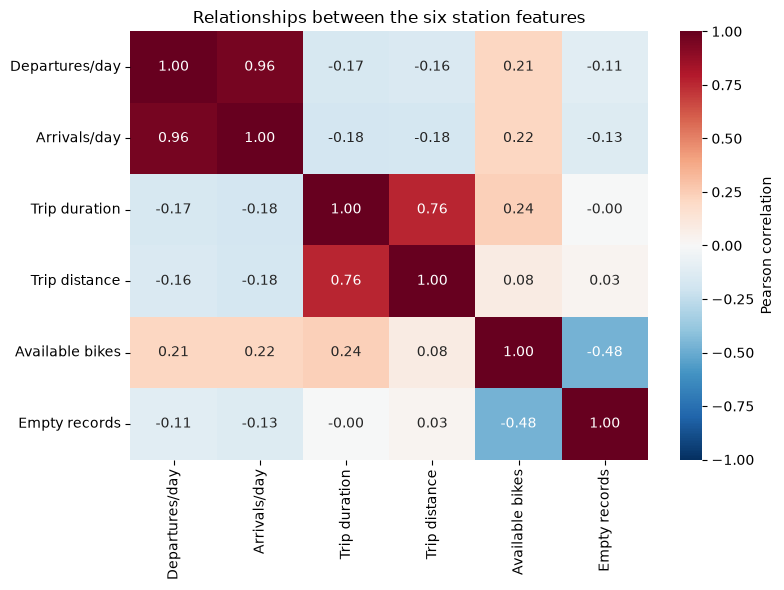

,,station_count,median_departures_per_day,median_duration_min,median_available_bikes,median_empty_share
city_id,system_name,,,,,
856,Sant Boi de Llobregat,10,15.722,15.702,5.112,0.065
848,Esplugues de Llobregat,11,12.910,16.274,4.086,0.109
639,Orlen Płock,19,9.464,14.144,6.842,0.040
422,Kołobrzeg,12,5.290,25.631,8.569,0.016
523,Ciechanów,10,3.992,19.229,6.942,0.026
431,Kalisz,16,3.575,23.065,7.633,0.000
496,Koszalin,20,3.387,23.209,8.107,0.009
710,Rendsburg,11,2.760,12.921,4.153,0.076
497,Sosnowiec,24,2.576,27.692,6.605,0.022


In [7]:
FEATURE_LABELS = {
    "departures_per_day": "Departures/day",
    "arrivals_per_day": "Arrivals/day",
    "avg_duration_min": "Trip duration",
    "avg_distance_km": "Trip distance",
    "avg_available_bikes": "Available bikes",
    "empty_record_share": "Empty records",
}
feature_summary = X.describe(percentiles=[0.10, 0.50, 0.90]).T
display(feature_summary[["mean", "10%", "50%", "90%", "max"]].round(3))

feature_correlations = X.corr()
display(feature_correlations.round(3))
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    feature_correlations.rename(index=FEATURE_LABELS, columns=FEATURE_LABELS),
    annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="RdBu_r", ax=ax,
    cbar_kws={"label": "Pearson correlation"},
)
ax.set_title("Relationships between the six station features")
fig.tight_layout()
plt.show()

system_summary = analysis_stations.groupby(["city_id", "system_name"]).agg(
    station_count=("departures_per_day", "size"),
    median_departures_per_day=("departures_per_day", "median"),
    median_duration_min=("avg_duration_min", "median"),
    median_available_bikes=("avg_available_bikes", "median"),
    median_empty_share=("empty_record_share", "median"),
)
larger_systems = system_summary.loc[system_summary["station_count"] >= 10]
display(larger_systems.sort_values("median_departures_per_day", ascending=False).head(10).round(3))

**Results.** Median activity is 0.76 departures and 0.72 arrivals per day. The departure-rate 90th percentile is 3.82, five times the median. Departure and arrival rates have r = 0.958; average duration and distance have r = 0.760.

Median average-bike availability is 4.13, with a maximum of 102.82. The median empty-record share is 4.5%, increasing to 17.2% at the 90th percentile. Availability and empty-record share have r = -0.476.

The selected sample covers 168 systems and 12 countries. Among 83 systems with at least 10 stations, median daily departures range from 0.12 to 15.72.

**Insights.** Borrowing and return rates contain substantial overlapping activity information. Supply and activity are uneven across stations, and system differences may contribute to later clusters.

## 7. Feature Standardization

**Purpose.** Prevent different measurement units from determining PCA contributions.

`StandardScaler` transforms each feature using:

`standardized value = (value - mean) / population standard deviation`

The check uses `ddof=0`, matching the scaler. Original-unit values remain available for interpretation. Standardization changes scale but does not remove outlier influence.

In [8]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=FEATURES)
scale_check = pd.DataFrame({
    "mean": X_scaled.mean(),
    "population_std": X_scaled.std(ddof=0),
})
display(scale_check.round(6))

,mean,population_std
departures_per_day,-0.0,1.0
arrivals_per_day,0.0,1.0
avg_duration_min,0.0,1.0
avg_distance_km,0.0,1.0
avg_available_bikes,-0.0,1.0
empty_record_share,0.0,1.0


**Results.** Column means are effectively zero and population standard deviations are one. Maximum numerical deviations are 1.24e-16 and 2.22e-16, respectively.

## 8. Principal Component Analysis

**Purpose.** Summarize related features while retaining most of their variation.

PCA forms weighted combinations of the standardized features. The smallest number of components reaching 90% cumulative explained variance is retained. This criterion measures feature variation, not clustering quality.

,component,explained_share,cumulative_share
0,PC1,0.377818,0.377818
1,PC2,0.298822,0.676641
2,PC3,0.197017,0.873658
3,PC4,0.083440,0.957098


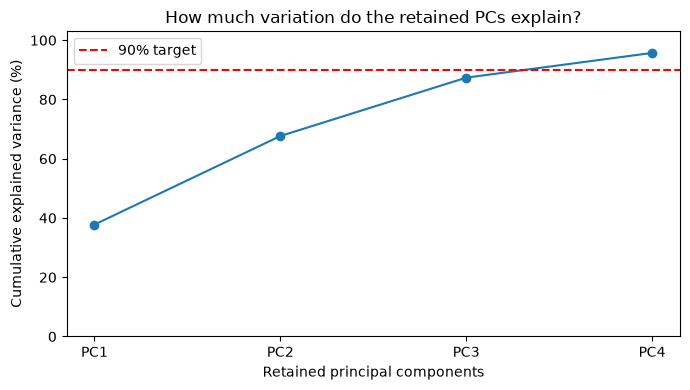

In [9]:
pca = PCA(n_components=0.90, svd_solver="full")
scores = pca.fit_transform(X_scaled)
pc_names = [f"PC{i + 1}" for i in range(pca.n_components_)]
pca_scores = pd.DataFrame(scores, index=X.index, columns=pc_names)

explained_variance = pd.DataFrame({
    "component": pc_names,
    "explained_share": pca.explained_variance_ratio_,
    "cumulative_share": np.cumsum(pca.explained_variance_ratio_),
})
display(explained_variance)

plt.figure(figsize=(7, 4))
plt.plot(pc_names, explained_variance["cumulative_share"] * 100, marker="o")
plt.axhline(90, color="red", linestyle="--", label="90% target")
plt.xlabel("Retained principal components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("How much variation do the retained PCs explain?")
plt.ylim(0, 103)
plt.legend()
plt.tight_layout()
plt.show()

**Results.** Four components explain 95.71% of standardized feature variation. PC1 and PC2 explain 67.66%, leaving 32.34% outside the two-dimensional view. All four components are retained, including the supply differences represented by PC3 and PC4.

## 9. Component Weights and Feature Associations

**Purpose.** Relate component scores to the station measurements.

Weights define each PC's formula; larger absolute weights indicate larger contributions. Feature-score correlations describe linear associations across stations and are reported separately. Reversing a component's sign leaves the PCA solution unchanged, so score signs do not indicate performance quality.

,PC1,PC2,PC3,PC4
departures_per_day,0.584,0.173,0.356,-0.068
arrivals_per_day,0.591,0.170,0.334,-0.078
avg_duration_min,-0.339,0.556,0.249,0.058
avg_distance_km,-0.350,0.499,0.347,-0.287
avg_available_bikes,0.186,0.514,-0.404,0.697
empty_record_share,-0.193,-0.344,0.645,0.646


,PC1,PC2,PC3,PC4
departures_per_day,0.879,0.232,0.387,-0.048
arrivals_per_day,0.890,0.227,0.363,-0.055
avg_duration_min,-0.511,0.744,0.270,0.041
avg_distance_km,-0.527,0.668,0.377,-0.203
avg_available_bikes,0.280,0.689,-0.439,0.493
empty_record_share,-0.290,-0.461,0.701,0.457


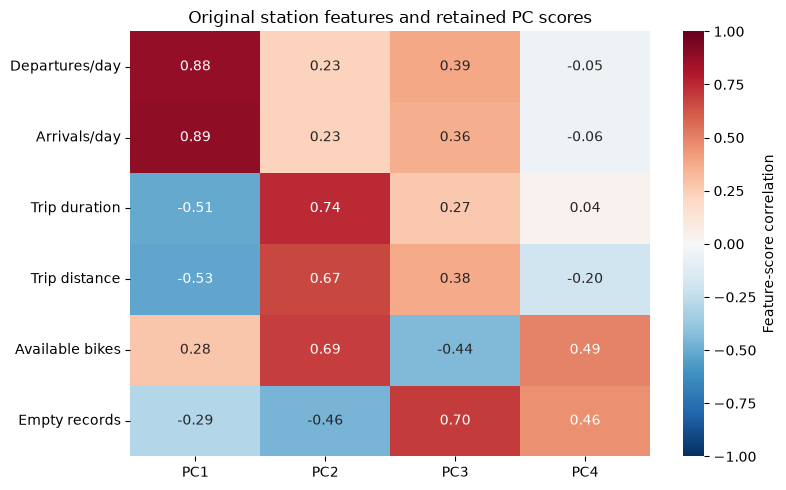

In [10]:
weights = pd.DataFrame(pca.components_.T, index=FEATURES, columns=pc_names)
display(weights.round(3))
feature_pc_correlations = pd.DataFrame({
    pc: X_scaled.corrwith(pca_scores[pc]) for pc in pc_names
})
display(feature_pc_correlations.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    feature_pc_correlations.rename(index=FEATURE_LABELS),
    annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="RdBu_r", ax=ax,
    cbar_kws={"label": "Feature-score correlation"},
)
ax.set_title("Original station features and retained PC scores")
fig.tight_layout()
plt.show()

**Results.** The strongest feature-score associations are:

| Component | Two strongest associations |
|---|---|
| PC1 | `arrivals_per_day` (+0.890); `departures_per_day` (+0.879) |
| PC2 | `avg_duration_min` (+0.744); `avg_available_bikes` (+0.689) |
| PC3 | `empty_record_share` (+0.701); `avg_available_bikes` (-0.439) |
| PC4 | `avg_available_bikes` (+0.493); `empty_record_share` (+0.457) |

Values are Pearson correlations. PC1 contrasts activity with trip length; PC2 combines trip length and supply. PC3 and PC4 retain further supply differences, examined in Section 10.

## 10. Quantitative Profiles Along the Components

**Purpose.** Interpret component directions in original feature units.

For each PC, feature medians are compared between the bottom and top score quartiles. These groups describe the fitted directions, not clusters or changes over time. They are derived from the PCA inputs and therefore do not independently validate station classes.

A separate PC4 table compares supply means, medians, and maxima to assess within-group variation.

In [11]:
profile_rows = []
for pc in pc_names:
    lower = pca_scores[pc] <= pca_scores[pc].quantile(0.25)
    upper = pca_scores[pc] >= pca_scores[pc].quantile(0.75)
    for group_name, mask in [("Bottom 25%", lower), ("Top 25%", upper)]:
        row = {"component": pc, "score_group": group_name, "stations": int(mask.sum())}
        row.update(X.loc[mask].median().to_dict())
        profile_rows.append(row)
component_profiles = pd.DataFrame(profile_rows)
display(component_profiles.round(3))

pc4_supply_rows = []
for group_name, mask in [
    ("Bottom 25%", pca_scores["PC4"] <= pca_scores["PC4"].quantile(0.25)),
    ("Top 25%", pca_scores["PC4"] >= pca_scores["PC4"].quantile(0.75)),
]:
    bikes = X.loc[mask, "avg_available_bikes"]
    pc4_supply_rows.append({
        "PC4 score group": group_name,
        "stations": len(bikes),
        "mean_available_bikes": bikes.mean(),
        "median_available_bikes": bikes.median(),
        "maximum_available_bikes": bikes.max(),
    })
pc4_supply_check = pd.DataFrame(pc4_supply_rows)
display(pc4_supply_check.round(3))

,component,score_group,stations,departures_per_day,arrivals_per_day,avg_duration_min,avg_distance_km,avg_available_bikes,empty_record_share
0,PC1,Bottom 25%,559,0.222,0.216,37.098,3.216,3.000,0.083
1,PC1,Top 25%,559,3.179,3.025,17.181,1.475,6.162,0.028
2,PC2,Bottom 25%,559,0.494,0.500,13.964,1.241,2.436,0.123
3,PC2,Top 25%,559,0.818,0.746,34.265,2.920,6.677,0.017
4,PC3,Bottom 25%,559,0.784,0.769,19.324,1.531,6.694,0.010
5,PC3,Top 25%,559,0.590,0.531,24.291,2.267,2.558,0.136
6,PC4,Bottom 25%,559,0.414,0.398,27.788,2.720,4.017,0.033
7,PC4,Top 25%,559,0.684,0.654,18.613,1.592,2.575,0.139


,PC4 score group,stations,mean_available_bikes,median_available_bikes,maximum_available_bikes
0,Bottom 25%,559,4.251,4.017,11.520
1,Top 25%,559,5.428,2.575,102.819


**Results.** Feature medians in the bottom and top score quartiles are:

| Component | Bottom quartile to top quartile |
|---|---|
| PC1 | Departures/day: 0.22 to 3.18; duration: 37.10 to 17.18 min; distance: 3.22 to 1.47 km |
| PC2 | Duration: 13.96 to 34.26 min; distance: 1.24 to 2.92 km; available bikes: 2.44 to 6.68 |
| PC3 | Empty-record share: 1.0% to 13.6%; available bikes: 6.69 to 2.56; departures/day: 0.78 to 0.59 |
| PC4 | Available bikes: 4.02 to 2.57; empty-record share: 3.3% to 13.9% |

**Insights.** PC3's upper quartile has more empty observations despite lower median daily departures. Activity alone does not capture recorded supply differences.

PC4's upper quartile has a higher mean available-bike count (5.43 versus 4.25), but a lower median (2.57 versus 4.02) and a larger maximum (102.82 versus 11.52). A higher PC4 score therefore does not imply uniformly greater supply. Group descriptions require medians or distributions alongside means.

## 11. Final Dataset and Clustering Interface

**Purpose.** Support clustering and original-unit interpretation through one station-level table.

| Role | Columns | Use |
|---|---|---|
| Reference | `station_id`, `city_id`, `system_name`, `country`, `lon`, `lat` | Link records, compare systems, and map results |
| Observation | `sample_days`, `departure_count`, `arrival_count`, `status_count` | Assess data support |
| Original features | Six features from Section 6 | Interpret station groups |
| Model input | `PC1`, `PC2`, `PC3`, `PC4` | Fit clustering models |

Clustering uses only the PC columns, without further standardization. Labels are joined by unique `station_id`, with one label per selected station. Original features support group summaries; reference and observation fields support contextual checks.

Export checks cover station uniqueness, row alignment, finite values, and the retained variance target. The final table is saved to `output/part_b/station_pca_scores.csv`.

In [12]:
assert pca_scores.index.is_unique
assert pca_scores.index.equals(X.index)
assert analysis_stations.index.equals(pca_scores.index)
assert np.isfinite(pca_scores.to_numpy()).all()
assert explained_variance["cumulative_share"].iloc[-1] >= 0.90
if len(pc_names) > 1:
    assert explained_variance["cumulative_share"].iloc[-2] < 0.90

REFERENCE_COLUMNS = ["city_id", "system_name", "country", "lon", "lat"]
OBSERVATION_COLUMNS = ["sample_days", "departure_count", "arrival_count", "status_count"]
final_table = analysis_stations[REFERENCE_COLUMNS + OBSERVATION_COLUMNS + FEATURES].join(pca_scores)
final_table = final_table.rename_axis("station_id").reset_index()
assert final_table["station_id"].is_unique
assert np.isfinite(final_table[FEATURES + pc_names + OBSERVATION_COLUMNS].to_numpy()).all()

clustering_input = final_table[pc_names].copy()
assert clustering_input.shape == pca_scores.shape
assert np.allclose(clustering_input, pca_scores)
final_table.to_csv(OUT_DIR / "station_pca_scores.csv", index=False, encoding="utf-8-sig")
display(final_table.head())

,station_id,city_id,system_name,country,lon,lat,sample_days,departure_count,arrival_count,status_count,departures_per_day,arrivals_per_day,avg_duration_min,avg_distance_km,avg_available_bikes,empty_record_share,PC1,PC2,PC3,PC4
0,405835,302,Malta,MT,14.481456,35.906836,132.0,27.0,21.0,61.0,0.204545,0.159091,14.333333,1.720082,1.262295,0.245902,-0.855210,-1.958096,1.090675,0.869050
1,47283600,729,Stacje Sponsorskie Nextbike LRM,PL,22.575650,51.250660,67.0,482.0,504.0,954.0,7.194030,7.522388,24.187068,2.139190,7.824948,0.007338,3.019545,1.401782,0.705537,-0.316306
2,72520083,431,Kalisz,PL,18.054160,51.748620,67.0,226.0,215.0,809.0,3.373134,3.208955,19.093068,1.829371,6.809642,0.000000,1.297954,0.451383,-0.509705,-0.269203
3,352763,281,Würzburg,DE,9.920923,49.797818,133.0,27.0,34.0,150.0,0.203008,0.255639,25.814815,1.079949,2.766667,0.040000,-0.324211,-0.746363,-0.698465,-0.312595
4,352762,281,Würzburg,DE,9.935843,49.801150,133.0,141.0,131.0,427.0,1.060150,0.984962,17.624113,1.404822,4.449649,0.063232,0.141476,-0.658741,-0.510507,0.029222


**Results.** The final table contains 2,235 stations and 20 columns: six reference fields, four observation fields, six original features, and four PC scores. All export checks pass.

## 12. Findings and Limitations

**Main findings.** Four PCs explain 95.71% of variation across 2,235 selected stations. Activity and trip length define the leading directions; supply and empty observations add distinct information. PC4's contrasting mean and median demonstrates why later cluster profiles should report distributions rather than group means alone.

**Limitations.** Unequal endpoint coverage and system sampling may affect activity comparisons. Minimum record counts do not ensure evenly spread observations or continuous station operation. Selection may underrepresent low-activity or poorly recorded stations.

Extreme values can influence feature means and PCA. Systems with more stations contribute more observations. Correlations and quartile comparisons do not control for capacity or system design and cannot establish causes.

**Further analysis.** Compare clustering methods and group counts using all four PCs, assessing separation, size, and stability. Interpret labels with the original features and system composition. Residential, commercial, or tourist labels require additional evidence.

## 13. Station Clustering

**Purpose.** Group stations with similar activity, trip characteristics, and bike availability, and interpret what each group reveals about how bike-sharing systems are used.

The analysis starts from the station table exported in Section 11. It is reloaded from the CSV file so that this part runs independently of the raw input paths used above.

In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

PART_B_DIR = Path("../output/part_b")
RANDOM_STATE = 0

station_table = pd.read_csv(PART_B_DIR / "station_pca_scores.csv")
FEATURES = [
    "departures_per_day", "arrivals_per_day", "avg_duration_min",
    "avg_distance_km", "avg_available_bikes", "empty_record_share",
]
SKEWED_FEATURES = FEATURES[:5]
display(station_table.shape)

(2235, 20)

### 13.1. Log Transformation of Skewed Features

**Purpose.** Limit the influence of a few extreme stations on PCA and clustering.

Section 6.1 showed strongly right-skewed features: the maximum average available-bike count is 102.8 against a median of 4.1, and the busiest station records 34 departures per day against a median of 0.76. A first clustering attempt on the Section 8 scores was dominated by these extremes: the best silhouette (k = 2) only separated 113 very active stations from the rest, clusters of two stations appeared from k = 5, and k = 4 solutions were unstable across subsamples (mean ARI 0.44).

`log1p(x) = log(1 + x)` is applied to the five count, duration, distance, and supply features. `log1p` is used instead of `log` because several values are close to zero. `empty_record_share` is a proportion bounded between 0 and 1 and is left unchanged.

,skew_raw,skew_after_transform
departures_per_day,4.96,1.41
arrivals_per_day,4.56,1.34
avg_duration_min,3.27,0.48
avg_distance_km,2.46,0.79
avg_available_bikes,11.69,0.32
empty_record_share,2.06,2.06


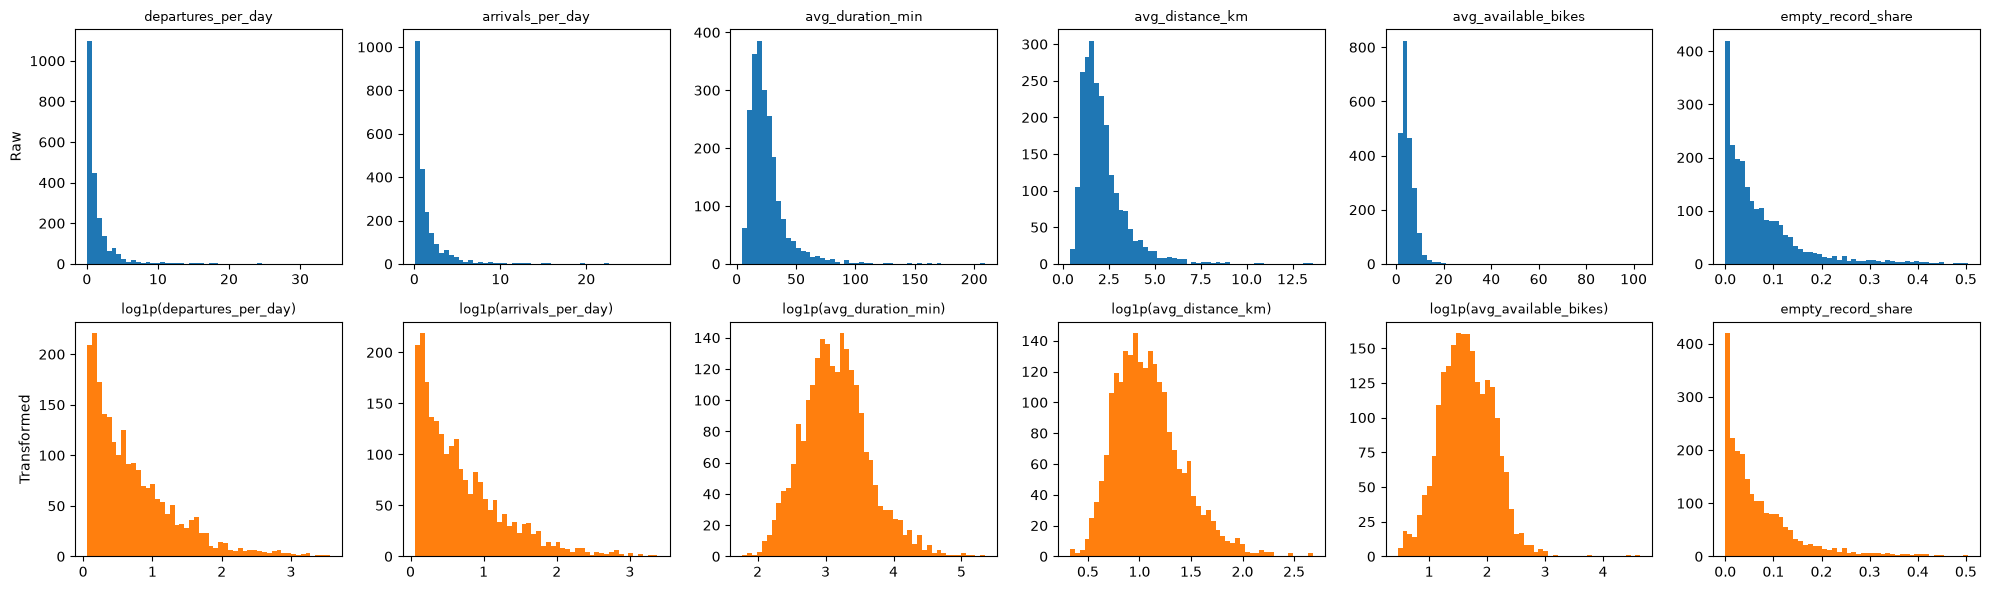

In [14]:
X_log = station_table[FEATURES].copy()
X_log[SKEWED_FEATURES] = np.log1p(X_log[SKEWED_FEATURES])

skew_check = pd.DataFrame({
    "skew_raw": station_table[FEATURES].skew(),
    "skew_after_transform": X_log.skew(),
})
display(skew_check.round(2))

fig, axes = plt.subplots(2, len(FEATURES), figsize=(20, 6))
for i, feature in enumerate(FEATURES):
    axes[0, i].hist(station_table[feature], bins=50)
    axes[0, i].set_title(feature, fontsize=9)
    axes[1, i].hist(X_log[feature], bins=50, color="tab:orange")
    axes[1, i].set_title(f"log1p({feature})" if feature in SKEWED_FEATURES else feature, fontsize=9)
axes[0, 0].set_ylabel("Raw")
axes[1, 0].set_ylabel("Transformed")
fig.tight_layout()
plt.show()

**Results.** Skewness falls from 2.5–11.7 to 0.3–1.4 for the five transformed features. `empty_record_share` keeps a skewness of 2.06, since most stations are rarely empty.

### 13.2. PCA on Transformed Features

**Purpose.** Recompute the components on the transformed features.

The Section 8 components were fitted on untransformed values and cannot be reused. The same procedure is applied: standardization, then the smallest number of components reaching 90% cumulative explained variance.

,component,explained_share,cumulative_share
0,PC1,0.442,0.442
1,PC2,0.319,0.761
2,PC3,0.169,0.931


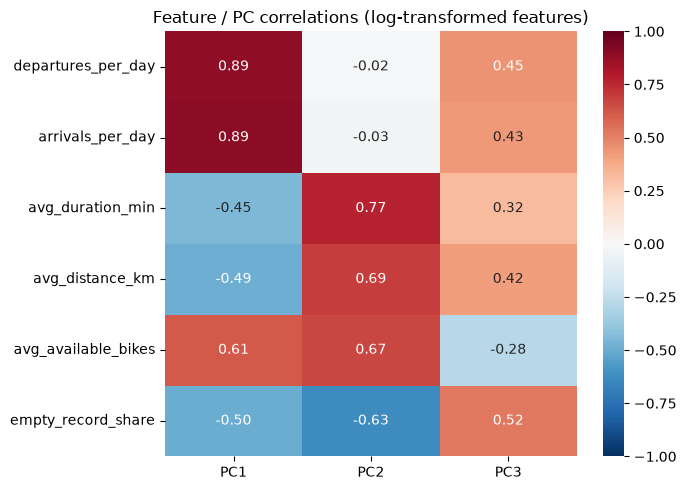

In [15]:
X_log_scaled = StandardScaler().fit_transform(X_log)
pca_log = PCA(n_components=0.90, svd_solver="full")
Z = pca_log.fit_transform(X_log_scaled)
log_pc_names = [f"PC{i + 1}" for i in range(pca_log.n_components_)]

display(pd.DataFrame({
    "component": log_pc_names,
    "explained_share": pca_log.explained_variance_ratio_,
    "cumulative_share": np.cumsum(pca_log.explained_variance_ratio_),
}).round(3))

feature_pc_corr = pd.DataFrame(
    {pc: [np.corrcoef(X_log_scaled[:, j], Z[:, i])[0, 1] for j in range(len(FEATURES))]
     for i, pc in enumerate(log_pc_names)},
    index=FEATURES,
)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(feature_pc_corr, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="RdBu_r", ax=ax)
ax.set_title("Feature / PC correlations (log-transformed features)")
fig.tight_layout()
plt.show()

**Results.** Three components explain 93.1% of the variance (44.2%, 31.9%, and 16.9%), compared with four components before the transformation.

| Component | Interpretation | Strongest correlations |
|---|---|---|
| PC1 | Station activity | departures/day (+0.89), arrivals/day (+0.89), available bikes (+0.61) |
| PC2 | Trip length and supply | duration (+0.77), distance (+0.69), available bikes (+0.67), empty records (−0.63) |
| PC3 | Shortage despite activity | empty records (+0.52), departures/day (+0.45), available bikes (−0.28) |

Departures and arrivals load almost identically on every component (r = 0.958 in Section 6.1). Activity therefore carries roughly double weight in the clustering input.

### 13.3. Choosing the Number of Clusters

**Purpose.** Select k with several complementary criteria rather than a single score.

For k = 2 to 10, KMeans is evaluated with:
- **inertia** (within-cluster sum of squares; the elbow method),
- **silhouette** (higher means better separated clusters),
- **Davies-Bouldin index** (lower means better separated clusters),
- **stability**: KMeans is refitted on ten random 80% subsamples, and each solution is compared with the full-data solution using the Adjusted Rand Index (1 = identical partitions),
- **smallest cluster size**, to avoid groups of only a few stations.

,inertia,silhouette,davies_bouldin,stability_ari,smallest_cluster
k,,,,,
2,8723.564,0.287,1.295,0.978,847
3,6539.235,0.297,1.148,0.930,691
4,5252.103,0.298,1.052,0.938,230
5,4472.091,0.271,1.091,0.940,187
6,3970.328,0.259,1.063,0.798,174
7,3590.178,0.259,1.060,0.719,85
8,3239.169,0.268,1.019,0.703,86
9,2933.806,0.266,0.985,0.796,76
10,2702.530,0.261,1.026,0.895,65


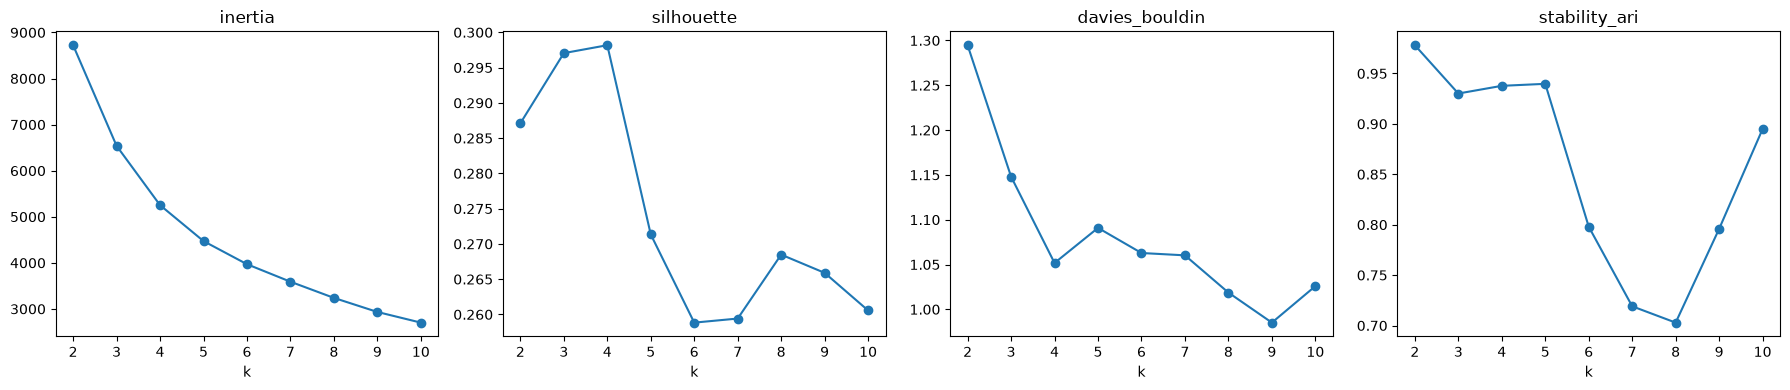

In [16]:
def kmeans_stability(data, k, n_runs=10, sample_frac=0.8):
    rng = np.random.default_rng(RANDOM_STATE)
    reference = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(data)
    scores = []
    for run in range(n_runs):
        sample = rng.choice(len(data), int(sample_frac * len(data)), replace=False)
        model = KMeans(n_clusters=k, n_init=10, random_state=run).fit(data[sample])
        scores.append(adjusted_rand_score(reference, model.predict(data)))
    return np.mean(scores)


k_rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    k_rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(Z, model.labels_),
        "davies_bouldin": davies_bouldin_score(Z, model.labels_),
        "stability_ari": kmeans_stability(Z, k),
        "smallest_cluster": np.bincount(model.labels_).min(),
    })
k_selection = pd.DataFrame(k_rows).set_index("k")
display(k_selection.round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, metric in zip(axes, ["inertia", "silhouette", "davies_bouldin", "stability_ari"]):
    ax.plot(k_selection.index, k_selection[metric], marker="o")
    ax.set_title(metric)
    ax.set_xlabel("k")
fig.tight_layout()
plt.show()

**Results.**
- Stability stays between 0.93 and 0.98 for k = 2 to 5, then falls to 0.70–0.80 for k = 6 to 9.
- Silhouette peaks at about 0.30 for k = 3 and 4 and decreases afterwards. This value indicates weak separation.
- The inertia curve has no sharp elbow.

k = 2 separates active from inactive stations only. **k = 4 is retained**: it is as stable as k = 3, has the best silhouette and a lower Davies-Bouldin index, and isolates a group of frequently empty stations that k = 3 merges with low-activity stations. Its smallest cluster still contains 230 stations.

### 13.4. Ward Hierarchical Clustering

**Purpose.** Check the KMeans choice with an independent hierarchical method.

Ward linkage merges, at each step, the two groups whose union least increases within-cluster variance. Large jumps in merge distance suggest natural cut levels. The tree is truncated to the last 30 merges for readability.

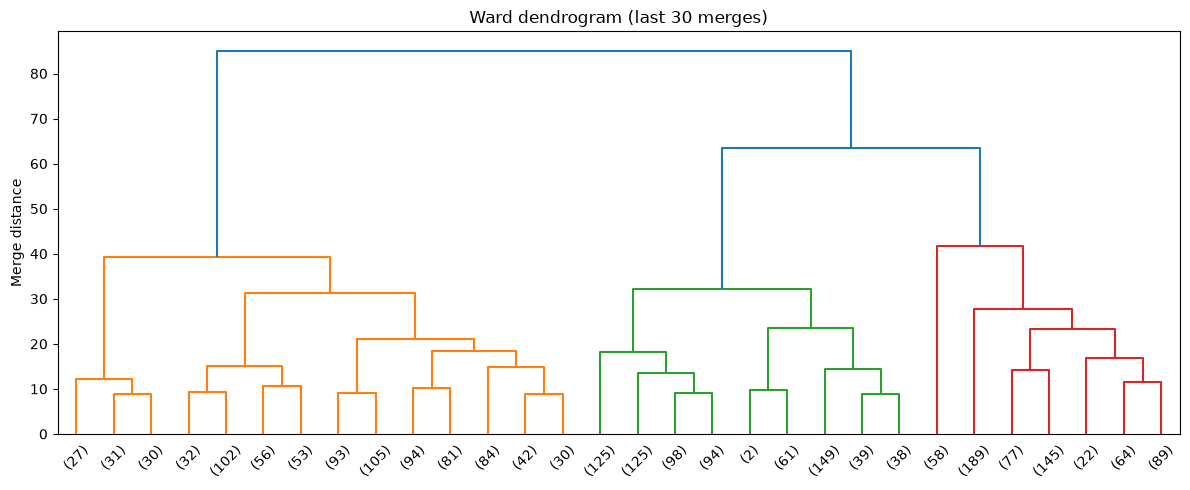

In [17]:
ward_tree = linkage(Z, method="ward")
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(ward_tree, truncate_mode="lastp", p=30, show_leaf_counts=True, ax=ax)
ax.set_title("Ward dendrogram (last 30 merges)")
ax.set_ylabel("Merge distance")
fig.tight_layout()
plt.show()

**Results.** The last merges occur at distances 85.1, 63.5, 41.6, 39.2, and 32.3. The largest gaps support two or three clusters. The 41.6 to 39.2 step is small, so the hierarchy gives no strong support for a fourth group. The choice of k = 4 rests on stability and interpretability rather than on the dendrogram.

### 13.5. Comparison of Clustering Methods

**Purpose.** Test whether the k = 4 partition depends on the algorithm.

- **KMeans** assumes compact, roughly spherical clusters.
- **Ward** builds a hierarchy with the same variance criterion but without random initialization.
- **Gaussian Mixture Model (GMM)** allows elliptical clusters of different shapes and sizes.

Agreement between methods is measured with the ARI.

In [18]:
K = 4

kmeans_labels = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit_predict(Z)
ward_labels = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z)
gmm_labels = GaussianMixture(n_components=K, n_init=5, random_state=RANDOM_STATE).fit_predict(Z)

method_labels = {"KMeans": kmeans_labels, "Ward": ward_labels, "GMM": gmm_labels}
display(pd.DataFrame({
    name: {
        "silhouette": silhouette_score(Z, labels),
        "davies_bouldin": davies_bouldin_score(Z, labels),
        "cluster_sizes": sorted(np.bincount(labels).tolist()),
    }
    for name, labels in method_labels.items()
}).T)
display(pd.DataFrame(
    [[adjusted_rand_score(a, b) for b in method_labels.values()] for a in method_labels.values()],
    index=method_labels.keys(), columns=method_labels.keys(),
).round(2))

,silhouette,davies_bouldin,cluster_sizes
KMeans,0.298178,1.051713,"[230, 515, 682, 808]"
Ward,0.27084,0.978682,"[58, 586, 731, 860]"
GMM,0.179055,1.561442,"[225, 461, 695, 854]"


,KMeans,Ward,GMM
KMeans,1.00,0.44,0.21
Ward,0.44,1.00,0.25
GMM,0.21,0.25,1.00


**Results.**

| Method | Silhouette | Davies-Bouldin | Cluster sizes |
|---|---|---|---|
| KMeans | 0.298 | 1.05 | 230, 515, 682, 808 |
| Ward | 0.271 | 0.98 | 58, 586, 731, 860 |
| GMM | 0.179 | 1.56 | 225, 461, 695, 854 |

Pairwise ARI is 0.44 between KMeans and Ward, 0.21 between KMeans and GMM, and 0.25 between Ward and GMM.

**Insights.** The methods agree only partly. Combined with silhouettes below 0.30, this indicates that stations do not form clearly separated natural types. They vary along continuous gradients of activity, trip length, and supply. The clusters are therefore a useful segmentation of this continuum, not distinct station categories. KMeans labels are retained for interpretation because they are the most stable and best separated.

### 13.6. Cluster Profiles

**Purpose.** Describe each cluster in original units.

Profiles use the untransformed features. Medians and boxplots are reported instead of means because Section 10 showed that group means can be driven by a few extreme stations.

,stations,departures_per_day,arrivals_per_day,avg_duration_min,avg_distance_km,avg_available_bikes,empty_record_share
cluster,,,,,,,
0,808,0.762,0.740,16.356,1.360,3.355,0.068
1,515,3.478,3.219,19.881,1.646,6.405,0.023
2,230,0.238,0.230,24.456,2.367,1.556,0.239
3,682,0.378,0.364,33.170,2.809,4.668,0.028


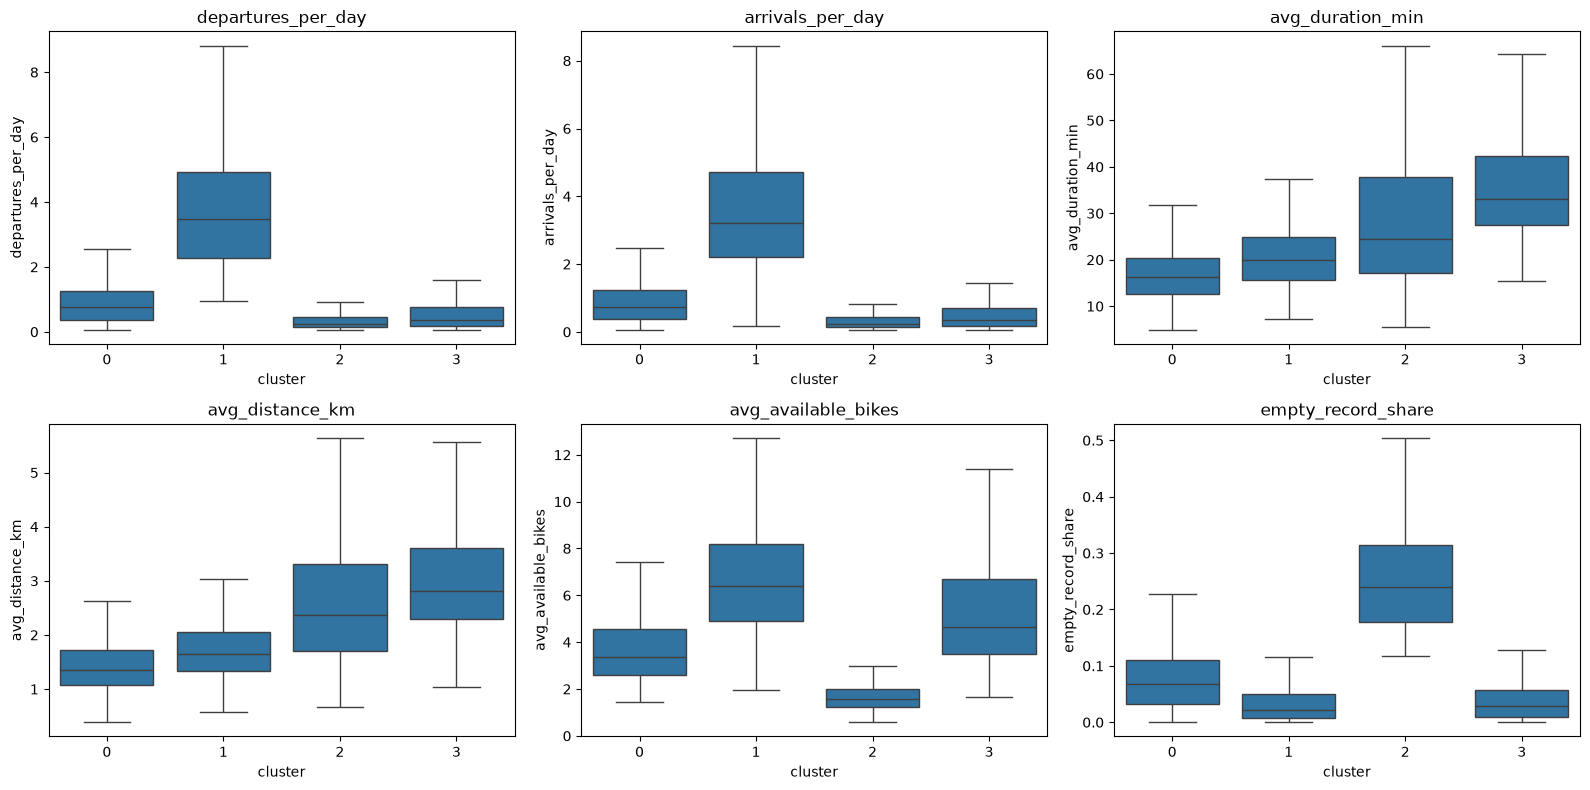

In [19]:
station_table["cluster"] = kmeans_labels

cluster_profiles = station_table.groupby("cluster")[FEATURES].median()
cluster_profiles.insert(0, "stations", station_table.groupby("cluster").size())
display(cluster_profiles.round(3))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feature in zip(axes.flat, FEATURES):
    sns.boxplot(data=station_table, x="cluster", y=feature, ax=ax, showfliers=False)
    ax.set_title(feature)
fig.tight_layout()
plt.show()

**Results.** Median feature values per cluster:

| Cluster | Stations | Departures/day | Duration (min) | Distance (km) | Available bikes | Empty records | Proposed profile |
|---|---|---|---|---|---|---|---|
| 1 | 515 | 3.48 | 19.9 | 1.65 | 6.40 | 2% | **Busy hubs** |
| 0 | 808 | 0.76 | 16.4 | 1.36 | 3.35 | 7% | **Short-hop local stations** |
| 3 | 682 | 0.38 | 33.2 | 2.81 | 4.67 | 3% | **Long-trip, low-use stations** |
| 2 | 230 | 0.24 | 24.5 | 2.37 | 1.56 | 24% | **Undersupplied stations** |

**Insights.**
- **Busy hubs** have about 4.6 times the median activity of the next cluster, yet are rarely empty. Their high supply suggests either larger capacity or active rebalancing.
- **Short-hop local stations** have the shortest trips (16 min, 1.4 km). This fits utilitarian, last-mile use.
- **Long-trip, low-use stations** have trips twice as long (33 min, 2.8 km) and are well stocked. This suggests leisure or peripheral locations where bikes are rarely taken.
- **Undersupplied stations** hold 1.6 bikes on median and are empty in about one record out of four, despite the lowest activity. Low use here may partly result from lack of bikes rather than lack of demand. These stations are the clearest targets for rebalancing.
- The arrival/departure ratio is between 0.93 and 0.97 in every cluster. Net flow does not distinguish the groups, partly because arrivals are undercounted (Section 4).

### 13.7. Clusters in PCA and Geographic Space

**Purpose.** Visualise cluster separation and spatial distribution.

The left panel shows stations in the plane of the first two components, which hold 76% of the variance. The right panel shows station coordinates coloured by cluster.

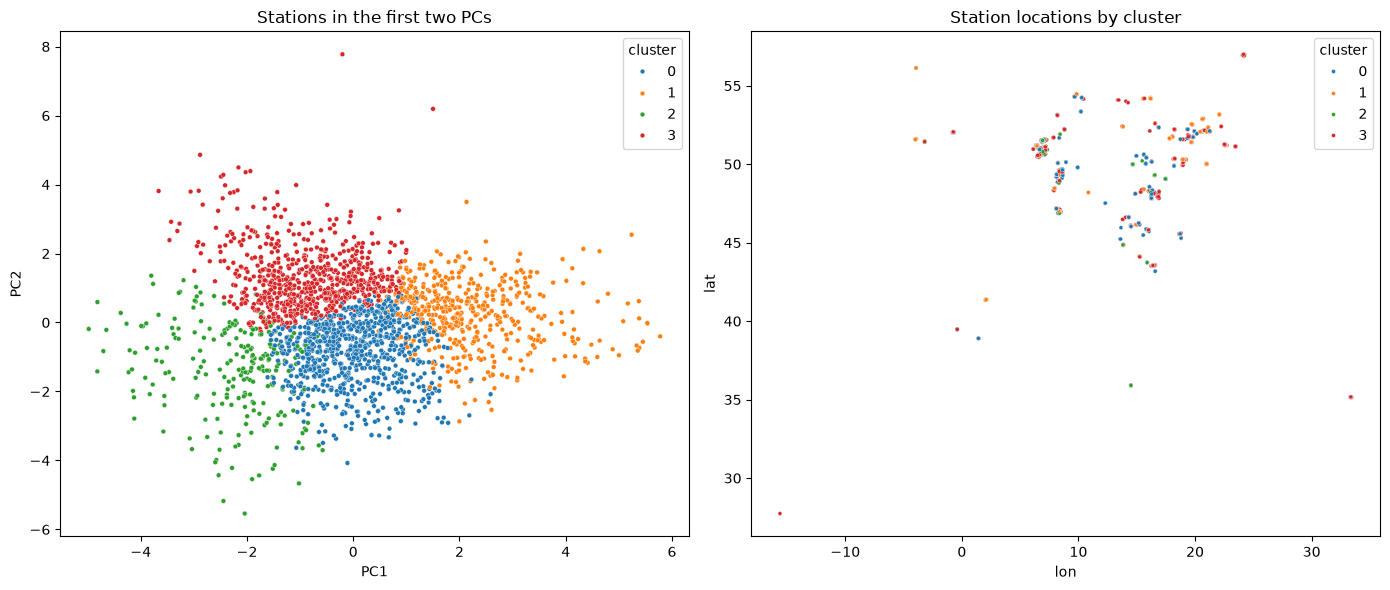

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=station_table["cluster"], palette="tab10", s=12, ax=axes[0])
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("Stations in the first two PCs")
sns.scatterplot(data=station_table, x="lon", y="lat", hue="cluster", palette="tab10", s=8, ax=axes[1])
axes[1].set_title("Station locations by cluster")
fig.tight_layout()
plt.show()

### 13.8. Cluster Composition by Country and System

**Purpose.** Check whether clusters describe station roles or simply reflect the country or system a station belongs to.

The country table gives the share of each country's stations in each cluster. For systems with at least 10 selected stations, `dominant_share` is the proportion of stations falling in the system's most frequent cluster.

In [21]:
country_mix = pd.crosstab(station_table["country"], station_table["cluster"], normalize="index")
country_mix.insert(0, "stations", station_table["country"].value_counts())
display(country_mix.sort_values("stations", ascending=False).round(2))

system_mix = pd.crosstab(station_table["system_name"], station_table["cluster"])
system_mix["stations"] = system_mix.sum(axis=1)
system_mix["dominant_share"] = system_mix.drop(columns="stations").max(axis=1) / system_mix["stations"]
display(system_mix.loc[system_mix["stations"] >= 10].sort_values("stations", ascending=False).head(20).round(2))

cluster,stations,0,1,2,3
country,,,,,
DE,719,0.41,0.13,0.17,0.29
PL,590,0.19,0.48,0.01,0.33
CZ,210,0.71,0.07,0.18,0.04
AT,197,0.42,0.09,0.03,0.46
CH,170,0.49,0.08,0.08,0.35
HR,108,0.30,0.29,0.06,0.35
GB,67,0.21,0.33,0.16,0.30
ES,51,0.33,0.55,0.02,0.10
SI,48,0.27,0.29,0.17,0.27


cluster,0,1,2,3,stations,dominant_share
system_name,,,,,,
Lublin,12,80,0,27,119,0.67
Mobic,36,4,19,41,100,0.41
Pardubice,43,1,8,2,54,0.80
Milton Keynes,13,11,4,17,45,0.38
Klagenfurt,11,5,0,29,45,0.64
Chorzów,19,14,0,10,43,0.44
Mödling,26,1,3,12,42,0.62
Uherské Hradiště,30,2,8,1,41,0.73
Sursee Plus,22,6,1,11,40,0.55


**Results.**
- Busy hubs are over-represented in Poland (48% of Polish stations) and Spain (55%), against 23% overall. In Lublin, 80 of 119 stations are busy hubs.
- In Rīga (Latvia), 82% of stations are long-trip, low-use stations. In Czechia, 71% are short-hop local stations.
- Undersupplied stations concentrate in some e-bike systems: 25 of 36 stations in RVK e-Bike and 20 of 30 in Bergisches e-Bike.
- Several systems are mixed: Ljubljana, Mülheim, and Milton Keynes have no cluster above 40%.

**Insights.** Clusters partly reflect system-level factors such as fleet size, pricing, rebalancing policy, or bike type, and not only the role of each station. The concentration of undersupplied stations in e-bike systems may relate to charging constraints, which could be checked against `bike_types`.

### 13.9. Export

**Purpose.** Save one cluster label per station so that station profiles can be compared with the trip clusters from Part A.

In [22]:
station_table[["station_id", "cluster"]].to_csv(PART_B_DIR / "station_clusters.csv", index=False)

## 14. Findings and Limitations

**Main findings.** After a log transformation, four stable station profiles emerge: busy hubs, short-hop local stations, long-trip low-use stations, and undersupplied stations. The undersupplied group (230 stations, empty in 24% of records) is the most directly useful for operations, because it identifies where bikes are missing rather than where demand is low. Country and system strongly shape cluster membership.

**Limitations.**
- Separation is weak (silhouette ≤ 0.30) and methods agree only partly (ARI 0.21–0.44). The profiles describe a continuum rather than distinct types.
- Departures and arrivals are almost redundant, giving activity double weight.
- Features are averaged over the whole period. They do not capture daily or weekly rhythms, which would better separate residential, commercial, and leisure stations.
- The selection in Section 6 excludes stations with little data, which removes part of the low-activity range.
- Station capacity is not used, so low supply cannot be distinguished from small stations.

**Further analysis.** Add hourly departure and arrival profiles (morning vs evening peaks), include capacity, and cross the station clusters with the Part A trip clusters.